# 03 — Baseline: o piso, os candidatos e o que as probabilidades significam

> Continua a análise exploratória (`01_eda.ipynb`). Antes de qualquer ajuste fino, um modelo
> precisa responder a três perguntas: **quanto ele ganha do que não exige modelo nenhum**, **as
> probabilidades que ele devolve são probabilidades de verdade**, e **ele generaliza para dado
> que não viu**. Este notebook responde às três, para modelos construídos aqui e para os dois
> candidatos que o pacote `credito` treina (`credito.model.train.treinar`, o mesmo código de
> `make train`).
>
> Para reexecutar: `poetry install --with notebooks` e depois `make baseline`.

**Disciplina de partições:** os modelos treinam na partição de **treino**; toda comparação e
toda escolha acontecem na **validação**; o **teste** é usado uma única vez, na seção 8, para
os números finais.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    log_loss,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

from credito.config import get_settings
from credito.data.arff import ler_arff
from credito.data.prepare import limpar, separar
from credito.model.train import treinar
from credito.schema import ALVO, FEATURES

warnings.filterwarnings("ignore", category=UserWarning)
pd.options.display.float_format = "{:,.4f}".format

# Paleta categórica validada, sempre na mesma ordem: cada modelo mantém a sua cor em todos os
# gráficos. Cinza neutro para as referências que não são modelos.
CORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
TINTA, TINTA_2, GRADE, FUNDO = "#0b0b0b", "#52514e", "#e5e4df", "#fcfcfb"
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "figure.facecolor": FUNDO,
        "axes.facecolor": FUNDO,
        "axes.edgecolor": TINTA_2,
        "axes.labelcolor": TINTA_2,
        "axes.titlecolor": TINTA,
        "axes.titlesize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRADE,
        "grid.linewidth": 0.8,
        "xtick.color": TINTA_2,
        "ytick.color": TINTA_2,
        "font.size": 10,
        "legend.frameon": False,
    }
)

settings = get_settings()
SEMENTE = settings.random_seed
X = list(FEATURES)
referencia, _ = limpar(ler_arff(settings.dataset_path))  # regras conferidas na EDA, seção 2.4
particoes = separar(
    referencia,
    test_size=settings.test_size,
    validation_size=settings.validation_size,
    seed=SEMENTE,
)
treino, validacao, teste = particoes["treino"], particoes["validacao"], particoes["teste"]
y_treino, y_val, y_teste = (
    treino[ALVO].to_numpy(),
    validacao[ALVO].to_numpy(),
    teste[ALVO].to_numpy(),
)
PREVALENCIA = y_val.mean()
print(
    {nome: len(p) for nome, p in particoes.items()},
    f"| inadimplência na validação: {PREVALENCIA:.4f}",
)

{'treino': 70749, 'validacao': 23584, 'teste': 23584} | inadimplência na validação: 0.0694


## 1. O piso: o que não precisa de modelo

Três referências, da mais ingênua à mais informada:

- **constante** — responde "adimplente" para todo mundo;
- **melhor variável sozinha** — ordena os clientes só pelo uso do rotativo, a variável de
  maior poder na EDA (IV 1,03);
- **regra de negócio** — recusa quem tem algum atraso de 90 dias ou mais, ou quem passou do
  limite do rotativo. Saiu dos dois achados mais fortes da EDA, sem nenhum ajuste.

In [2]:
def metricas_de_decisao(y, recusa) -> dict[str, float]:
    recusa = np.asarray(recusa, dtype=bool)
    vp = (recusa & (y == 1)).sum()
    return {
        "acurácia": float(((recusa) == (y == 1)).mean()),
        "recall": float(vp / (y == 1).sum()),
        "precisão": float(vp / recusa.sum()) if recusa.any() else np.nan,
        "aprovação": float(1 - recusa.mean()),
    }


regra = (validacao["NumberOfTimes90DaysLate"] > 0) | (
    validacao["RevolvingUtilizationOfUnsecuredLines"] > 1
)
piso = pd.DataFrame(
    {
        "constante": {
            **metricas_de_decisao(y_val, np.zeros(len(y_val))),
            "AUC-PR": PREVALENCIA,
            "AUC-ROC": 0.5,
        },
        "melhor variável (uso_rotativo)": {
            "AUC-PR": average_precision_score(
                y_val, validacao["RevolvingUtilizationOfUnsecuredLines"]
            ),
            "AUC-ROC": roc_auc_score(y_val, validacao["RevolvingUtilizationOfUnsecuredLines"]),
        },
        "regra de negócio": metricas_de_decisao(y_val, regra),
    }
).T
display(piso[["AUC-PR", "AUC-ROC", "acurácia", "recall", "precisão", "aprovação"]])

,AUC-PR,AUC-ROC,acurácia,recall,precisão,aprovação
constante,0.0694,0.5000,0.9306,0.0000,NaN,1.0000
melhor variável (uso_rotativo),0.1966,0.7664,NaN,NaN,NaN,NaN
regra de negócio,NaN,NaN,0.9127,0.3940,0.3768,0.9274


- **Constante:** 93,06% de acurácia e nenhum inadimplente identificado — a armadilha da
  acurácia que a EDA já mostrou.
- **Melhor variável sozinha:** ordenar só pelo uso do rotativo dá AUC-PR de 0,197, 2,8 vezes o
  acaso, e AUC-ROC de 0,766. Uma variável já faz boa parte do trabalho.
- **Regra de negócio com duas condições:** recusa 7,3% dos pedidos e pega **39% dos
  inadimplentes com precisão de 38%** — sem treinar nada.

A regra é o número a bater. Um modelo só se justifica se fizer melhor que ela — e a seção 5
mostra que faz: com a mesma precisão, o gradient boosting pega 50% dos inadimplentes, 11
pontos a mais que a regra.

## 2. Os candidatos

| Candidato | O que é | Por que entra |
|---|---|---|
| regressão logística | as dez variáveis padronizadas | o modelo linear mais simples |
| regressão logística com WoE | cada variável em faixas, codificada pelo *weight of evidence* do treino | o scorecard clássico de crédito; captura as relações em U da EDA |
| gradient boosting | `HistGradientBoostingClassifier`, parâmetros padrão | árvores, sem ajuste nenhum |
| **projeto: logística com peso** | `treinar(..., "regressao_logistica")` | o candidato linear do pacote |
| **projeto: XGBoost com peso** | `treinar(..., "xgboost")` | o candidato publicado |

Os três primeiros são treinados **sem** peso de classe: o desbalanceamento é tratado depois,
na escolha do limiar. Os dois do projeto usam peso de classe (`class_weight="balanced"` e
`scale_pos_weight`). A seção 4 mostra por que essa diferença importa.

In [3]:
CONTAGENS = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfDependents",
]


class CodificadorWoE:
    # As mesmas faixas da EDA (decis para as contínuas, 0 a 4+ para as contagens), com os
    # cortes e o WoE aprendidos só no treino.
    def fit(self, frame: pd.DataFrame, y: np.ndarray) -> "CodificadorWoE":
        self.cortes, self.woe = {}, {}
        for coluna in X:
            if coluna in CONTAGENS:
                faixas = frame[coluna].clip(upper=4)
            else:
                cortes = np.unique(np.quantile(frame[coluna], np.linspace(0, 1, 11)))
                cortes[0], cortes[-1] = -np.inf, np.inf
                self.cortes[coluna] = cortes
                faixas = pd.cut(frame[coluna], cortes, labels=False, include_lowest=True)
            tabela = pd.crosstab(faixas, y)
            bons = (tabela[0] + 0.5) / (tabela[0].sum() + 0.5)
            maus = (tabela[1] + 0.5) / (tabela[1].sum() + 0.5)
            self.woe[coluna] = np.log(bons / maus)
        return self

    def transform(self, frame: pd.DataFrame) -> pd.DataFrame:
        saida = {}
        for coluna in X:
            if coluna in CONTAGENS:
                faixas = frame[coluna].clip(upper=4)
            else:
                faixas = pd.cut(
                    frame[coluna], self.cortes[coluna], labels=False, include_lowest=True
                )
            saida[coluna] = faixas.map(self.woe[coluna]).fillna(0.0).to_numpy()
        return pd.DataFrame(saida, index=frame.index)


class LogisticaWoE:
    def fit(self, frame, y):
        self.codificador = CodificadorWoE().fit(frame, y)
        self.modelo = LogisticRegression(max_iter=1000).fit(self.codificador.transform(frame), y)
        return self

    def predict_proba(self, frame):
        return self.modelo.predict_proba(self.codificador.transform(frame))


modelos = {
    "regressão logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(
        treino[X], y_treino
    ),
    "logística com WoE": LogisticaWoE().fit(treino[X], y_treino),
    "gradient boosting": HistGradientBoostingClassifier(random_state=SEMENTE).fit(
        treino[X], y_treino
    ),
    "projeto: logística com peso": treinar(treino, "regressao_logistica", seed=SEMENTE),
    "projeto: XGBoost com peso": treinar(treino, "xgboost", seed=SEMENTE),
}
COR = dict(zip(modelos, CORES, strict=False))
p_val = {nome: m.predict_proba(validacao[X])[:, 1] for nome, m in modelos.items()}


def resumo(y, p) -> dict[str, float]:
    return {
        "AUC-PR": average_precision_score(y, p),
        "AUC-PR / prevalência": average_precision_score(y, p) / y.mean(),
        "AUC-ROC": roc_auc_score(y, p),
        "Brier": brier_score_loss(y, p),
        "log loss": log_loss(y, p),
        "risco médio previsto": p.mean(),
        "inadimplência real": y.mean(),
    }


comparacao = pd.DataFrame({nome: resumo(y_val, p) for nome, p in p_val.items()}).T
display(comparacao.sort_values("AUC-PR", ascending=False))

,AUC-PR,AUC-PR / prevalência,AUC-ROC,Brier,log loss,risco médio previsto,inadimplência real
gradient boosting,0.3784,5.4516,0.8530,0.0519,0.1880,0.0703,0.0694
logística com WoE,0.3675,5.2949,0.8464,0.0529,0.1921,0.0704,0.0694
projeto: XGBoost com peso,0.3612,5.2034,0.8437,0.1308,0.4147,0.2917,0.0694
projeto: logística com peso,0.3469,4.9971,0.8123,0.1614,0.5355,0.3818,0.0694
regressão logística,0.3401,4.9001,0.8052,0.0552,0.2082,0.0702,0.0694


### 2.1 As diferenças são maiores que o acaso?

A validação é uma amostra; outra amostra daria outros números. O bootstrap pareado reamostra
os mesmos clientes para todos os modelos, 1.000 vezes, e mede a diferença de AUC-PR de cada
um contra o melhor da tabela.

In [4]:
melhor = comparacao["AUC-PR"].idxmax()
gerador = np.random.default_rng(SEMENTE)
diferencas = {nome: [] for nome in modelos if nome != melhor}
for _ in range(1000):
    indice = gerador.integers(len(y_val), size=len(y_val))
    referencia_b = average_precision_score(y_val[indice], p_val[melhor][indice])
    for nome in diferencas:
        diferencas[nome].append(
            average_precision_score(y_val[indice], p_val[nome][indice]) - referencia_b
        )
pareado = pd.DataFrame(
    {
        nome: {
            "diferença de AUC-PR": np.mean(d),
            "IC95 inferior": np.quantile(d, 0.025),
            "IC95 superior": np.quantile(d, 0.975),
            "pior que o melhor?": "sim" if np.quantile(d, 0.975) < 0 else "não dá para afirmar",
        }
        for nome, d in diferencas.items()
    }
).T
print(f"referência: {melhor}")
display(pareado)

referência: gradient boosting


,diferença de AUC-PR,IC95 inferior,IC95 superior,pior que o melhor?
regressão logística,-0.0380,-0.0502,-0.0253,sim
logística com WoE,-0.0106,-0.0201,-0.0012,sim
projeto: logística com peso,-0.0312,-0.0434,-0.0190,sim
projeto: XGBoost com peso,-0.0169,-0.0269,-0.0068,sim


- **O gradient boosting sem nenhum ajuste tem a maior AUC-PR** (0,378, 5,5 vezes o acaso).
- **A logística com WoE fica logo atrás dele**: a diferença (−0,011, intervalo de −0,020 a
  −0,001) é pequena, mas não cruza o zero.
  É o scorecard clássico de crédito — um coeficiente por faixa de cada variável, legível por
  quem revisa uma decisão. Codificar as variáveis em faixas, como a EDA sugeriu por causa das
  relações em U, é o que leva a logística de 0,340 a 0,368.
- **O XGBoost do projeto é pior que o gradient boosting sem ajuste** (−0,017, intervalo de
  −0,027 a −0,007). A seção 7 mostra por quê.
- **Nas colunas de ordenação (AUC-PR, AUC-ROC) os modelos ficam próximos. Nas de calibração
  (Brier, risco médio previsto) os dois candidatos do projeto se separam de todos os outros**
  — o risco médio que eles preveem é de 29% e 38%, numa validação onde a inadimplência real é
  de 6,9%. É o assunto da seção 4.

## 3. Curvas de precisão-recall e ROC

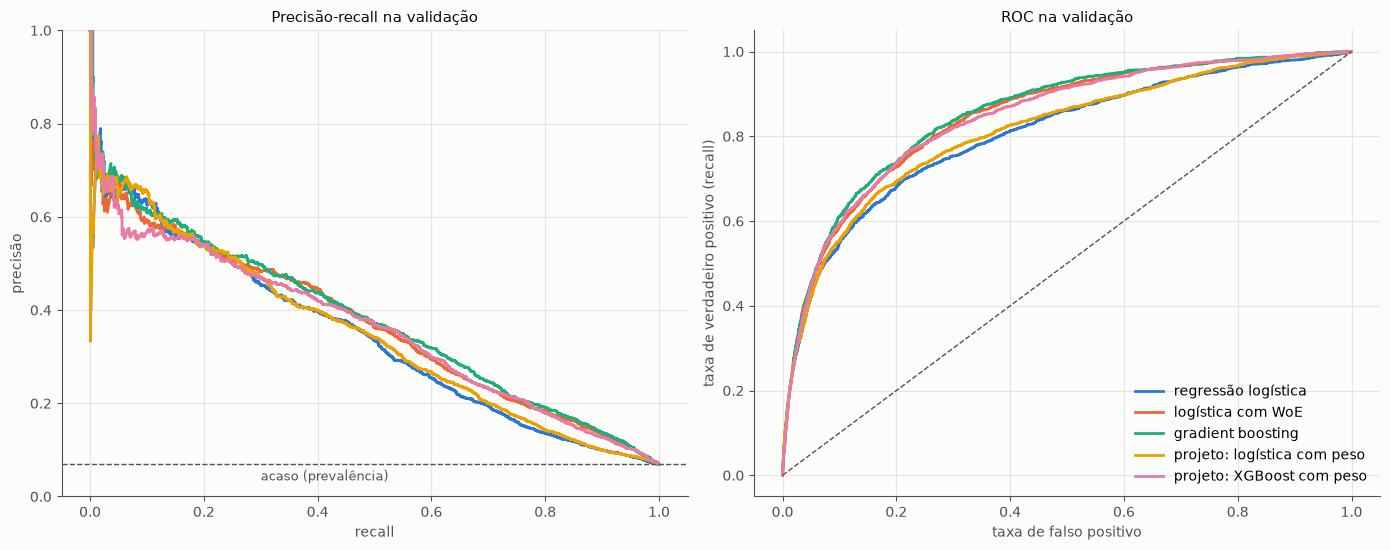

In [5]:
fig, (ax_pr, ax_roc) = plt.subplots(1, 2, figsize=(14, 5.6))
for nome, p in p_val.items():
    precisao, recall, _ = precision_recall_curve(y_val, p)
    ax_pr.plot(recall, precisao, color=COR[nome], linewidth=2, label=nome)
    fpr, tpr, _ = roc_curve(y_val, p)
    ax_roc.plot(fpr, tpr, color=COR[nome], linewidth=2, label=nome)
ax_pr.axhline(PREVALENCIA, color=TINTA_2, linestyle="--", linewidth=1)
ax_pr.text(0.3, PREVALENCIA - 0.035, "acaso (prevalência)", color=TINTA_2, fontsize=9)
ax_pr.set(xlabel="recall", ylabel="precisão", title="Precisão-recall na validação", ylim=(0, 1))
ax_roc.plot([0, 1], [0, 1], color=TINTA_2, linestyle="--", linewidth=1)
ax_roc.set(
    xlabel="taxa de falso positivo",
    ylabel="taxa de verdadeiro positivo (recall)",
    title="ROC na validação",
)
ax_roc.legend(loc="lower right")
fig.tight_layout()
plt.show()

As curvas se sobrepõem em boa parte. Gradient boosting, logística com WoE e o XGBoost do
projeto ficam juntos no alto; as duas logísticas sobre as variáveis brutas ficam um pouco
abaixo, sobretudo na faixa intermediária de recall. **A escolha do modelo muda pouco a
ordenação.** O que separa os modelos de verdade está na próxima seção.

## 4. As probabilidades são probabilidades?

Um modelo de crédito não devolve só uma ordem: devolve um número que vai ser lido como
"chance de inadimplir" — por quem revisa a decisão, por quem monitora a carteira, pelo
próprio cliente. A **calibração** pergunta: entre os clientes a quem o modelo atribui 20%, cerca
de 20% inadimplem de fato?

O gráfico agrupa a validação em dez faixas de probabilidade prevista (decis) e compara a
média prevista de cada faixa com a taxa observada. Um modelo calibrado fica na diagonal.

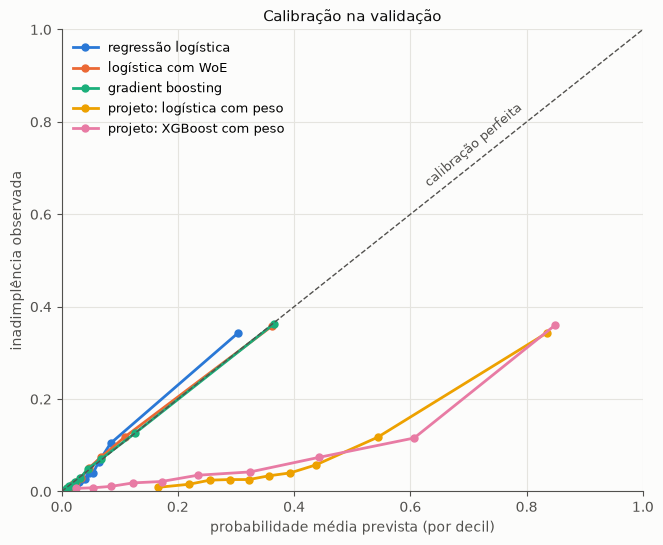

,risco médio previsto,inadimplência real,Brier,previsto / real
regressão logística,0.0702,0.0694,0.0552,1.0115
logística com WoE,0.0704,0.0694,0.0529,1.0137
gradient boosting,0.0703,0.0694,0.0519,1.0133
projeto: logística com peso,0.3818,0.0694,0.1614,5.5004
projeto: XGBoost com peso,0.2917,0.0694,0.1308,4.2028


In [6]:
def confiabilidade(y, p, faixas: int = 10) -> pd.DataFrame:
    grupo = pd.qcut(p, faixas, labels=False, duplicates="drop")
    return pd.DataFrame({"previsto": p, "observado": y}).groupby(grupo).mean()


fig, ax = plt.subplots(figsize=(7.5, 6))
for nome, p in p_val.items():
    tabela = confiabilidade(y_val, p)
    ax.plot(
        tabela["previsto"],
        tabela["observado"],
        color=COR[nome],
        linewidth=2,
        marker="o",
        markersize=5,
        label=nome,
    )
ax.plot([0, 1], [0, 1], color=TINTA_2, linestyle="--", linewidth=1)
ax.text(0.62, 0.66, "calibração perfeita", color=TINTA_2, fontsize=9, rotation=40)
ax.set(
    xlim=(0, 1),
    ylim=(0, 1),
    xlabel="probabilidade média prevista (por decil)",
    ylabel="inadimplência observada",
    title="Calibração na validação",
)
ax.legend(loc="upper left", fontsize=9)
plt.show()

display(
    comparacao[["risco médio previsto", "inadimplência real", "Brier"]].assign(
        **{"previsto / real": comparacao["risco médio previsto"] / comparacao["inadimplência real"]}
    )
)

**Os três modelos treinados sem peso estão calibrados**: preveem em média 7,0% para uma
inadimplência real de 6,94% (razão de 1,01), e os pontos ficam sobre a diagonal.

**Os dois candidatos do projeto não estão.** O XGBoost prevê em média 29,2% — **4,2 vezes** a
taxa real —, e a logística, 38,2% (5,5 vezes). No decil em que o XGBoost diz cerca de 60%, a
inadimplência observada é de cerca de 12%. O Brier, que mede o erro da probabilidade, é 2,5 a 3
vezes pior.

**Por que isso importa fora do notebook.** O número que esses modelos devolvem é tratado
como probabilidade: a API de scoring o expõe no campo `probabilidade_inadimplencia`, e é ele
que um revisor humano veria ao reavaliar uma decisão. Um pedido que sai com 24,7% corresponde,
corrigido pela fórmula da seção 4.1, a cerca de 2,4%. Qualquer uso do número como chance —
perda esperada, precificação, explicação ao cliente — fica errado por um fator de quatro.

### 4.1 O peso de classe é uma mudança de limiar disfarçada

Para isolar o efeito do peso, o mesmo XGBoost do projeto — mesmos hiperparâmetros, mesma
semente — é treinado de novo **sem** `scale_pos_weight`. Três perguntas:

1. O peso melhora a **ordenação** (AUC-PR, AUC-ROC)?
2. O modelo sem peso, com o limiar escolhido para pegar a mesma fração de inadimplentes,
   decide **igual**?
3. Dá para **corrigir** a probabilidade do modelo com peso sem retreinar? Um peso $w$ na
   classe positiva multiplica as chances previstas por cerca de $w$; dividir de volta,
   $p' = \frac{p}{p + w\,(1 - p)}$, é a correção clássica de mudança de prior.

In [7]:
xgb_projeto = modelos["projeto: XGBoost com peso"]
parametros = xgb_projeto[-1].get_params()
peso = parametros["scale_pos_weight"]
sem_peso = XGBClassifier(**{**parametros, "scale_pos_weight": 1.0}).fit(treino[X], y_treino)
p_com, p_sem = p_val["projeto: XGBoost com peso"], sem_peso.predict_proba(validacao[X])[:, 1]
p_corrigido = p_com / (p_com + peso * (1 - p_com))

recusa_com = p_com >= 0.5
recall_alvo = recusa_com[y_val == 1].mean()
limiar_sem = float(np.quantile(p_sem[y_val == 1], 1 - recall_alvo))
recusa_sem = p_sem >= limiar_sem

peso_isolado = pd.DataFrame(
    {
        "com peso, limiar 0,5": {
            **resumo(y_val, p_com),
            **metricas_de_decisao(y_val, recusa_com),
            "limiar": 0.5,
        },
        "sem peso, limiar ajustado": {
            **resumo(y_val, p_sem),
            **metricas_de_decisao(y_val, recusa_sem),
            "limiar": limiar_sem,
        },
        # A correção é monotônica: o limiar 0,5 vira 1 / (1 + w) e as decisões não mudam.
        "com peso, probabilidade corrigida": {
            **resumo(y_val, p_corrigido),
            **metricas_de_decisao(y_val, p_corrigido >= 1 / (1 + peso)),
            "limiar": 1 / (1 + peso),
        },
    }
).T
print(f"scale_pos_weight do projeto: {peso:.2f}")
display(
    peso_isolado[
        [
            "AUC-PR",
            "AUC-ROC",
            "limiar",
            "recall",
            "precisão",
            "aprovação",
            "risco médio previsto",
            "inadimplência real",
            "Brier",
        ]
    ]
)
concordancia = (recusa_com == recusa_sem).mean()
print(f"decisões idênticas entre as duas primeiras linhas: {concordancia:.2%}")

scale_pos_weight do projeto: 13.40


,AUC-PR,AUC-ROC,limiar,recall,precisão,aprovação,risco médio previsto,inadimplência real,Brier
"com peso, limiar 0,5",0.3612,0.8437,0.5000,0.6970,0.2325,0.7919,0.2917,0.0694,0.1308
"sem peso, limiar ajustado",0.3705,0.8504,0.0857,0.6970,0.2428,0.8008,0.0701,0.0694,0.0524
"com peso, probabilidade corrigida",0.3612,0.8437,0.0694,0.6970,0.2325,0.7919,0.0603,0.0694,0.0529


decisões idênticas entre as duas primeiras linhas: 95.45%


1. **O peso não melhora a ordenação.** Sem peso, o mesmo XGBoost tem AUC-PR de 0,370, contra
   0,361 com peso.
2. **O peso não muda as decisões, só o limiar.** Sem peso, um limiar de 0,086 pega a mesma
   fração de inadimplentes (recall 0,697), com precisão de 0,243 contra 0,232 e aprovação de
   80,1% contra 79,2%. **95,5% das decisões são idênticas.**
3. **A correção de prior devolve a calibração sem retreinar e sem mudar nenhuma decisão.** O
   Brier cai de 0,131 para 0,053, o mesmo nível dos modelos sem peso, e o risco médio passa a
   6,0% (a inadimplência real é 6,9%).

**O peso de classe não ensina o modelo a enxergar melhor a classe rara: ele move o ponto onde
"0,5" cai.** O desbalanceamento se trata do mesmo jeito escolhendo o limiar — e sem estragar a
probabilidade. Para um modelo com peso já publicado, a correção da fórmula acima conserta o
número exposto sem retreinar.

## 5. O ponto de operação

A base não tem valor de empréstimo nem margem (EDA, seção 10), então o custo de cada erro não
pode ser medido aqui e **o limiar não pode ser escolhido por custo neste notebook**. O que dá
para fazer é mostrar o que cada limiar compra e custa, para que a escolha seja do negócio.
A tabela usa o gradient boosting sem peso, por clientes da validação e normalizada para
10.000 pedidos.

In [8]:
p_gb = p_val["gradient boosting"]
linhas = []
for recall_desejado in (0.5, 0.6, 0.7, 0.8, 0.9):
    limiar = float(np.quantile(p_gb[y_val == 1], 1 - recall_desejado))
    recusa = p_gb >= limiar
    por_10k = 10_000 / len(y_val)
    linhas.append(
        {
            "recall": recall_desejado,
            "limiar (probabilidade)": limiar,
            "aprovados": (~recusa).sum() * por_10k,
            "inadimplentes aprovados (FN)": (~recusa & (y_val == 1)).sum() * por_10k,
            "bons pagadores recusados (FP)": (recusa & (y_val == 0)).sum() * por_10k,
            "inadimplentes recusados (VP)": (recusa & (y_val == 1)).sum() * por_10k,
            "precisão": (recusa & (y_val == 1)).sum() / recusa.sum(),
            "FP por inadimplente evitado": (recusa & (y_val == 0)).sum()
            / (recusa & (y_val == 1)).sum(),
        }
    )
operacao = pd.DataFrame(linhas).set_index("recall")
pd.options.display.float_format = "{:,.2f}".format
display(operacao)
pd.options.display.float_format = "{:,.4f}".format

,limiar (probabilidade),aprovados,inadimplentes aprovados (FN),bons pagadores recusados (FP),inadimplentes recusados (VP),precisão,FP por inadimplente evitado
recall,,,,,,,
0.50,0.20,"9,064.20",346.85,588.53,347.27,0.37,1.69
0.60,0.14,"8,692.76",277.73,890.86,416.38,0.32,2.14
0.70,0.09,"8,034.26",208.19,"1,479.82",485.92,0.25,3.05
0.80,0.06,"7,094.22",139.08,"2,350.75",555.04,0.19,4.24
0.90,0.03,"5,443.10",69.54,"3,932.33",624.58,0.14,6.30


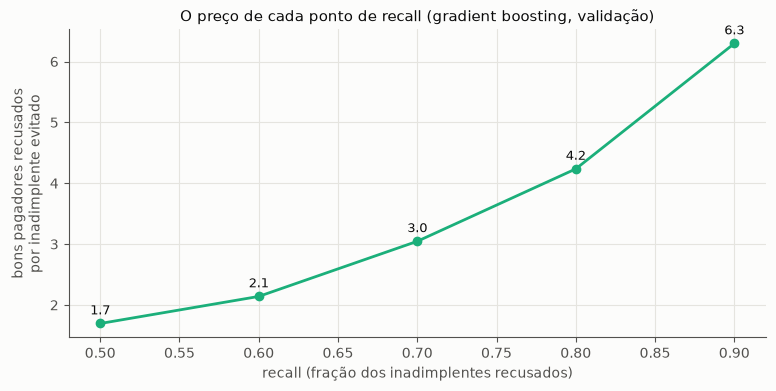

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(
    operacao.index,
    operacao["FP por inadimplente evitado"],
    color=CORES[2],
    linewidth=2,
    marker="o",
    markersize=6,
)
for x, y in operacao["FP por inadimplente evitado"].items():
    ax.text(x, y + 0.15, f"{y:.1f}", ha="center", color=TINTA, fontsize=9)
ax.set(
    xlabel="recall (fração dos inadimplentes recusados)",
    ylabel="bons pagadores recusados\npor inadimplente evitado",
    title="O preço de cada ponto de recall (gradient boosting, validação)",
)
plt.show()

Cada ponto de recall custa mais que o anterior. Olhando a **margem** — quantos bons pagadores a
mais são recusados para evitar cada inadimplente a mais:

| Passo de recall | Bons pagadores recusados a mais, por inadimplente evitado a mais |
|---|---:|
| de 0,5 para 0,6 | 4,4 |
| de 0,6 para 0,7 | 8,5 |
| de 0,7 para 0,8 | 12,6 |
| de 0,8 para 0,9 | 22,7 |

**Essa tabela transforma a escolha do limiar numa pergunta de negócio com resposta
objetiva:** quanto custa aprovar um inadimplente, em número de bons pagadores recusados? Se a
resposta for 10, o ponto certo fica entre recall 0,7 e 0,8; se for 5, perto de 0,6. É a
premissa que falta para escolher o limiar por custo.

## 6. Matriz de confusão no ponto de recall 0,70

In [10]:
limiar_70 = float(operacao.loc[0.7, "limiar (probabilidade)"])
recusa_70 = p_gb >= limiar_70
matriz = pd.DataFrame(
    [
        [(~recusa_70 & (y_val == 0)).sum(), (recusa_70 & (y_val == 0)).sum()],
        [(~recusa_70 & (y_val == 1)).sum(), (recusa_70 & (y_val == 1)).sum()],
    ],
    index=["adimplente (real)", "inadimplente (real)"],
    columns=["aprovado", "recusado"],
)
display(matriz)
inadimplem_recusados = matriz.loc["inadimplente (real)", "recusado"] / matriz["recusado"].sum()
inadimplem_aprovados = matriz.loc["inadimplente (real)", "aprovado"] / matriz["aprovado"].sum()
print(
    f"limiar {limiar_70:.4f} | inadimplem entre os recusados: {inadimplem_recusados:.1%} "
    f"| entre os aprovados: {inadimplem_aprovados:.1%}"
)

,aprovado,recusado
adimplente (real),18457,3490
inadimplente (real),491,1146


limiar 0.0896 | inadimplem entre os recusados: 24.7% | entre os aprovados: 2.6%


No ponto de recall 0,70, de 23.584 pedidos da validação, o modelo recusa 4.636: 1.146
inadimplentes e 3.490 bons pagadores. **De cada 100 recusados, 25 inadimpliriam.** Entre os
aprovados, a inadimplência cai para 2,6%, contra 6,9% da base — **uma carteira aprovada com
62% menos inadimplência**, ao preço de recusar 16% dos bons pagadores.

O limiar desse ponto, 0,0896, é uma probabilidade de verdade, porque o modelo está calibrado:
recusa-se quem tem mais de 9% de chance estimada de inadimplir.

## 7. Overfitting: treino contra validação

In [11]:
ajuste = pd.DataFrame(
    {
        nome: {
            "AUC-PR treino": average_precision_score(y_treino, m.predict_proba(treino[X])[:, 1]),
            "AUC-PR validação": average_precision_score(y_val, p_val[nome]),
            "AUC-ROC treino": roc_auc_score(y_treino, m.predict_proba(treino[X])[:, 1]),
            "AUC-ROC validação": roc_auc_score(y_val, p_val[nome]),
        }
        for nome, m in modelos.items()
    }
).T
ajuste["queda de AUC-PR"] = ajuste["AUC-PR treino"] - ajuste["AUC-PR validação"]
ajuste["queda relativa"] = ajuste["queda de AUC-PR"] / ajuste["AUC-PR treino"]
display(ajuste)

,AUC-PR treino,AUC-PR validação,AUC-ROC treino,AUC-ROC validação,queda de AUC-PR,queda relativa
regressão logística,0.3420,0.3401,0.8030,0.8052,0.0019,0.0055
logística com WoE,0.3788,0.3675,0.8477,0.8464,0.0113,0.0297
gradient boosting,0.4489,0.3784,0.8772,0.8530,0.0705,0.1571
projeto: logística com peso,0.3468,0.3469,0.8099,0.8123,-0.0001,-0.0002
projeto: XGBoost com peso,0.5376,0.3612,0.9236,0.8437,0.1764,0.3281


- As logísticas não perdem nada do treino para a validação: são simples demais para decorar.
- O gradient boosting perde 16% da AUC-PR — esperado para árvores. Ele para de crescer
  sozinho quando o desempenho numa fatia interna do treino deixa de melhorar (*early
  stopping*, padrão para bases com mais de 10 mil linhas).
- **O XGBoost do projeto perde 33%**: AUC-PR de 0,538 no treino contra 0,361 na validação, e
  AUC-ROC de 0,924 contra 0,844. Ele treina sempre 300 árvores, sem parada antecipada, e
  decora o treino — o dobro da perda do gradient boosting. É a explicação mais provável para
  ele perder do gradient boosting sem ajuste na seção 2.

## 8. O teste, uma única vez

Os dois modelos que seguem — o melhor do notebook e o candidato publicado — medidos no teste,
com intervalo de confiança por bootstrap (1.000 reamostras).

In [12]:
def com_ic(y, p, metrica, reamostras: int = 1000) -> str:
    gerador = np.random.default_rng(SEMENTE)
    valores = []
    for _ in range(reamostras):
        indice = gerador.integers(len(y), size=len(y))
        valores.append(metrica(y[indice], p[indice]))
    baixo, alto = np.quantile(valores, [0.025, 0.975])
    return f"{metrica(y, p):.4f} [{baixo:.4f}, {alto:.4f}]"


finais = {
    "gradient boosting": modelos["gradient boosting"],
    "projeto: XGBoost com peso": xgb_projeto,
}
p_teste = {nome: m.predict_proba(teste[X])[:, 1] for nome, m in finais.items()}
teste_final = pd.DataFrame(
    {
        nome: {
            "AUC-PR [IC95]": com_ic(y_teste, p, average_precision_score),
            "AUC-ROC [IC95]": com_ic(y_teste, p, roc_auc_score),
            "Brier [IC95]": com_ic(y_teste, p, brier_score_loss),
            "risco médio previsto": f"{p.mean():.4f}",
            "inadimplência real": f"{y_teste.mean():.4f}",
        }
        for nome, p in p_teste.items()
    }
).T
display(teste_final)

,AUC-PR [IC95],AUC-ROC [IC95],Brier [IC95],risco médio previsto,inadimplência real
gradient boosting,"0.3919 [0.3675, 0.4192]","0.8528 [0.8438, 0.8626]","0.0515 [0.0492, 0.0536]",0.0685,0.0694
projeto: XGBoost com peso,"0.3716 [0.3480, 0.3983]","0.8421 [0.8323, 0.8521]","0.1283 [0.1257, 0.1306]",0.2880,0.0694


O teste confirma a validação:

- **Ordenação:** gradient boosting com AUC-PR de 0,392 e AUC-ROC de 0,853; XGBoost do projeto
  com 0,372 e 0,842. Os intervalos individuais se sobrepõem, mas a comparação pareada da seção
  2.1 já tinha mostrado que a diferença não é acaso — e o teste mantém a direção.
- **Calibração:** Brier de 0,051 contra 0,128, e risco médio previsto de 6,9% contra 28,8%
  para uma inadimplência real de 6,9%. Aqui não há sobreposição nenhuma.

## 9. Conclusões

1. **O piso é alto.** Uma regra de duas condições, tirada da EDA, pega 39% dos inadimplentes
   com 38% de precisão. O modelo se justifica porque pega 50% com a mesma precisão.
2. **O melhor modelo é o mais simples de árvore.** Um gradient boosting com parâmetros padrão
   e sem peso supera o XGBoost publicado (AUC-PR de 0,392 contra 0,372 no teste). A logística
   com WoE fica logo atrás dele na validação e é interpretável — candidata natural quando a decisão
   precisa ser explicada.
3. **As probabilidades do modelo publicado estão infladas em cerca de 4 vezes.** O peso de
   classe só desloca o limiar e cobra isso com a calibração. Há dois consertos: treinar sem
   peso e escolher o limiar; ou, sem retreinar, aplicar a correção de prior antes de expor o
   número — as decisões não mudam.
4. **O XGBoost publicado decora o treino** (33% de queda de AUC-PR para a validação), por
   treinar 300 árvores sem parada antecipada.
5. **O limiar precisa de uma premissa de custo.** A tabela da seção 5 diz exatamente qual: em
   quantos bons pagadores recusados se mede o custo de um inadimplente aprovado.